# DeepFake Detection System: A Multimodal Approach
## Model Baseline: AVoiD-DF (IEEE TIFS 2023)
**Target Dataset:** LAV-DF (Localized Audio-Visual DeepFake Dataset)  
**Execution Environment:** Kaggle GPU Notebook (`/kaggle/input/` Read-Only & `/kaggle/working/` Writable Output)  

---
This notebook implements the complete **AVoiD-DF** multimodal deepfake detection pipeline for the **LAV-DF** dataset.
All dataset files under `/kaggle/input/` remain **100% read-only and untouched**. The 1000-video experiment is executed purely via in-memory selection and lazy loading.


### Section 1: Environment Setup & Dependency Verification


In [19]:
!pip install -q opencv-python torchaudio torchvision scikit-learn matplotlib pandas pillow tqdm


### Section 2: Import Core Libraries


In [20]:
import os
import sys
import glob
import json
import math
import copy
import random
from collections import OrderedDict
from functools import partial

import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

try:
    import torchaudio
    import torchaudio.transforms as AT
    HAS_TORCHAUDIO = True
except ImportError:
    HAS_TORCHAUDIO = False

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

print("=" * 60)
print("RESEARCH ENVIRONMENT INITIALIZATION")
print("=" * 60)
print(f"  Python Version:  {sys.version.split()[0]}")
print(f"  PyTorch Version: {torch.__version__}")
print(f"  TorchAudio Available: {HAS_TORCHAUDIO}")
print(f"  CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU Device:      {torch.cuda.get_device_name(0)}")
print("=" * 60)


RESEARCH ENVIRONMENT INITIALIZATION
  Python Version:  3.12.13
  PyTorch Version: 2.10.0+cu128
  TorchAudio Available: True
  CUDA Available:  True
  GPU Device:      Tesla T4


### Section 3: GPU Device Allocation


In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Capability: {torch.cuda.get_device_capability(0)}")


Active Compute Device: cuda
GPU Capability: (7, 5)


### Section 4: Scalable Experiment Configuration (100 -> 1000 Videos)
Configures the experiment in memory without modifying the read-only dataset under `/kaggle/input/`.


In [22]:
# --- EXPERIMENT SCALING CONFIGURATION ---
# Full experiment: TOTAL_VIDEOS = 1000 (500 Real, 500 Fake)
TOTAL_VIDEOS = 1000
NUM_REAL = 500
NUM_FAKE = 500
SEED = 42

# Stratified Split Proportions (60% Train, 20% Val, 20% Test)
TRAIN_REAL = 300
TRAIN_FAKE = 300
VAL_REAL = 100
VAL_FAKE = 100
TEST_REAL = 100
TEST_FAKE = 100

# Hyperparameters
BATCH_SIZE = 4
EPOCHS = 5
LEARNING_RATE = 1e-4
NUM_FRAMES = 16
IMG_SIZE = 224

print("=" * 60)
print("EXPERIMENT CONFIGURATION LOADED")
print("=" * 60)
print(f"  Total Target Videos: {TOTAL_VIDEOS} ({NUM_REAL} Real, {NUM_FAKE} Fake)")
print(f"  Train Allocation:   {TRAIN_REAL + TRAIN_FAKE} ({TRAIN_REAL} Real, {TRAIN_FAKE} Fake)")
print(f"  Val Allocation:     {VAL_REAL + VAL_FAKE} ({VAL_REAL} Real, {VAL_FAKE} Fake)")
print(f"  Test Allocation:    {TEST_REAL + TEST_FAKE} ({TEST_REAL} Real, {TEST_FAKE} Fake)")
print(f"  Random Seed:        {SEED}")
print("=" * 60)


EXPERIMENT CONFIGURATION LOADED
  Total Target Videos: 1000 (500 Real, 500 Fake)
  Train Allocation:   600 (300 Real, 300 Fake)
  Val Allocation:     200 (100 Real, 100 Fake)
  Test Allocation:    200 (100 Real, 100 Fake)
  Random Seed:        42


### Section 5: Configure Output Directories (Strictly `/kaggle/working/`)


In [23]:
KAGGLE_INPUT_DIR = "/kaggle/input"
KAGGLE_WORKING_DIR = "/kaggle/working"

WORKING_DIR = KAGGLE_WORKING_DIR if os.path.exists(KAGGLE_WORKING_DIR) else "./output"
RESULTS_DIR = os.path.join(WORKING_DIR, "AVoiD_DF_results")
WEIGHTS_DIR = os.path.join(RESULTS_DIR, "weights")

os.makedirs(WEIGHTS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Working Root: {WORKING_DIR}")
print(f"Results Dir:  {RESULTS_DIR}")
print(f"Weights Dir:  {WEIGHTS_DIR}")


Working Root: /kaggle/working
Results Dir:  /kaggle/working/AVoiD_DF_results
Weights Dir:  /kaggle/working/AVoiD_DF_results/weights


### Section 6: Auto-Discover LAV-DF Dataset Path


In [24]:
def auto_discover_lav_df():
    possible_roots = [
        "/kaggle/input/localized-audio-visual-deepfake-dataset-lav-df",
        "/kaggle/input/localized-audio-visual-deepfake-dataset-lav-df/LAV-DF",
        "/kaggle/input/lav-df",
        "/kaggle/input/lav_df",
        "./data/lav-df",
        "../lav-df",
        "./lav-df"
    ]
    
    if os.path.exists(KAGGLE_INPUT_DIR):
        contents = os.listdir(KAGGLE_INPUT_DIR)
        print(f"Contents of {KAGGLE_INPUT_DIR}: {contents}")
        for item in contents:
            if "lav" in item.lower() or "deepfake" in item.lower():
                candidate = os.path.join(KAGGLE_INPUT_DIR, item)
                if os.path.isdir(candidate):
                    # Check if there is a subfolder LAV-DF
                    sub = os.path.join(candidate, "LAV-DF")
                    if os.path.exists(sub) and os.path.isdir(sub):
                        return sub
                    return candidate

    for p in possible_roots:
        if os.path.exists(p):
            return p
            
    return KAGGLE_INPUT_DIR

DATASET_ROOT = auto_discover_lav_df()
print(f"Discovered Dataset Root Path: {DATASET_ROOT}")


Contents of /kaggle/input: ['datasets']
Discovered Dataset Root Path: /kaggle/input


### Section 7: Parse Metadata & Discover Real/Fake Samples


In [25]:
def discover_samples_with_metadata(root_path):
    print("=" * 60)
    print("READING LAV-DF METADATA & DATASET STRUCTURE")
    print("=" * 60)
    
    real_samples = []
    fake_samples = []
    
    # 1. Search for JSON metadata files
    json_files = glob.glob(os.path.join(root_path, "**", "*.json"), recursive=True)
    metadata_entries = {}
    
    for jf in json_files:
        try:
            with open(jf, "r") as f:
                data = json.load(f)
                if isinstance(data, list):
                    for item in data:
                        if isinstance(item, dict) and "file" in item:
                            metadata_entries[os.path.basename(item["file"])] = item
                elif isinstance(data, dict):
                    for k, v in data.items():
                        if isinstance(v, dict):
                            metadata_entries[k] = v
        except Exception:
            pass
            
    print(f"Parsed Metadata JSON Entries: {len(metadata_entries)}")
    
    # 2. Scan MP4 files
    mp4_files = glob.glob(os.path.join(root_path, "**", "*.mp4"), recursive=True)
    print(f"Total MP4 Videos Found in Dataset: {len(mp4_files)}")
    
    for video_path in mp4_files:
        bname = os.path.basename(video_path)
        label = None
        
        # Check metadata JSON record first
        if bname in metadata_entries:
            meta = metadata_entries[bname]
            n_fakes = meta.get("n_fakes", meta.get("num_fakes", None))
            if n_fakes is not None:
                label = 0 if n_fakes == 0 else 1
                
        # Fallback to directory/path analysis if metadata record is missing
        if label is None:
            path_lower = video_path.lower()
            if "real" in path_lower or "original" in path_lower or "/0/" in path_lower:
                label = 0
            elif "fake" in path_lower or "synthesis" in path_lower or "forged" in path_lower or "/1/" in path_lower:
                label = 1
            else:
                label = 0 # Default fallback
                
        if label == 0:
            real_samples.append(video_path)
        else:
            fake_samples.append(video_path)
            
    print(f"Total Discovered Real Samples: {len(real_samples)}")
    print(f"Total Discovered Fake Samples: {len(fake_samples)}")
    print("=" * 60)
    return real_samples, fake_samples

ALL_REAL_VIDEOS, ALL_FAKE_VIDEOS = discover_samples_with_metadata(DATASET_ROOT)


READING LAV-DF METADATA & DATASET STRUCTURE
Parsed Metadata JSON Entries: 136304
Total MP4 Videos Found in Dataset: 136304
Total Discovered Real Samples: 36431
Total Discovered Fake Samples: 99873


### Section 8: Balanced Sample Selection & Stratified Split Generation
Selects 50 Real + 50 Fake videos using `SEED = 42` and creates the 60 Train / 20 Val / 20 Test split.


In [26]:
random.seed(SEED)
np.random.seed(SEED)

# Handle cases where real/fake count in root is smaller than request
num_real_to_select = min(NUM_REAL, len(ALL_REAL_VIDEOS))
num_fake_to_select = min(NUM_FAKE, len(ALL_FAKE_VIDEOS))

selected_real = random.sample(ALL_REAL_VIDEOS, num_real_to_select) if len(ALL_REAL_VIDEOS) >= num_real_to_select else ALL_REAL_VIDEOS
selected_fake = random.sample(ALL_FAKE_VIDEOS, num_fake_to_select) if len(ALL_FAKE_VIDEOS) >= num_fake_to_select else ALL_FAKE_VIDEOS

print(f"Selected Real Videos: {len(selected_real)}")
print(f"Selected Fake Videos: {len(selected_fake)}")

# Stratified Split Allocation
train_real_cnt = min(TRAIN_REAL, int(len(selected_real) * 0.6))
val_real_cnt = min(VAL_REAL, int(len(selected_real) * 0.2))

train_fake_cnt = min(TRAIN_FAKE, int(len(selected_fake) * 0.6))
val_fake_cnt = min(VAL_FAKE, int(len(selected_fake) * 0.2))

train_real = selected_real[:train_real_cnt]
val_real = selected_real[train_real_cnt:train_real_cnt + val_real_cnt]
test_real = selected_real[train_real_cnt + val_real_cnt:]

train_fake = selected_fake[:train_fake_cnt]
val_fake = selected_fake[train_fake_cnt:train_fake_cnt + val_fake_cnt]
test_fake = selected_fake[train_fake_cnt + val_fake_cnt:]

train_videos = train_real + train_fake
train_labels = [0] * len(train_real) + [1] * len(train_fake)

val_videos = val_real + val_fake
val_labels = [0] * len(val_real) + [1] * len(val_fake)

test_videos = test_real + test_fake
test_labels = [0] * len(test_real) + [1] * len(test_fake)

# Shuffle splits internally
def shuffle_pair(v_list, l_list):
    combined = list(zip(v_list, l_list))
    random.shuffle(combined)
    return [x[0] for x in combined], [x[1] for x in combined]

train_videos, train_labels = shuffle_pair(train_videos, train_labels)
val_videos, val_labels = shuffle_pair(val_videos, val_labels)
test_videos, test_labels = shuffle_pair(test_videos, test_labels)

print("=" * 60)
print("STRATIFIED EXPERIMENT SPLIT COMPUTED")
print("=" * 60)
print(f"  Training Split:   {len(train_videos)} samples ({train_labels.count(0)} Real, {train_labels.count(1)} Fake)")
print(f"  Validation Split: {len(val_videos)} samples ({val_labels.count(0)} Real, {val_labels.count(1)} Fake)")
print(f"  Testing Split:    {len(test_videos)} samples ({test_labels.count(0)} Real, {test_labels.count(1)} Fake)")
print("=" * 60)


Selected Real Videos: 500
Selected Fake Videos: 500
STRATIFIED EXPERIMENT SPLIT COMPUTED
  Training Split:   600 samples (300 Real, 300 Fake)
  Validation Split: 200 samples (100 Real, 100 Fake)
  Testing Split:    200 samples (100 Real, 100 Fake)


### Section 9: Save Split References Metadata to `/kaggle/working/`
Saves ONLY file references/IDs and labels to JSON (no media files are copied).


In [27]:
split_metadata = {
    "experiment_config": {
        "total_videos": TOTAL_VIDEOS,
        "seed": SEED,
        "train_count": len(train_videos),
        "val_count": len(val_videos),
        "test_count": len(test_videos)
    },
    "train_split": [{"path": p, "label": l} for p, l in zip(train_videos, train_labels)],
    "val_split": [{"path": p, "label": l} for p, l in zip(val_videos, val_labels)],
    "test_split": [{"path": p, "label": l} for p, l in zip(test_videos, test_labels)]
}

SPLIT_JSON_PATH = os.path.join(RESULTS_DIR, "AVoiD_DF_1000_video_split.json")
with open(SPLIT_JSON_PATH, "w") as f:
    json.dump(split_metadata, f, indent=4)

print(f"Saved experiment split references to: {SPLIT_JSON_PATH}")


Saved experiment split references to: /kaggle/working/AVoiD_DF_results/AVoiD_DF_1000_video_split.json


### Section 10: Lazy PyTorch Dataset Class (`LAVDFDataset`)
Loads video frames and audio spectrograms lazily on `__getitem__`. Handles loading failures cleanly without synthetic random noise.


In [28]:
class LAVDFDataset(Dataset):
    def __init__(self, video_files, labels, num_frames=16, img_size=224, is_train=True):
        super().__init__()
        self.video_files = video_files
        self.labels = labels
        self.num_frames = num_frames
        self.img_size = img_size
        self.is_train = is_train
        
        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
        ])
        
        cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
        self.face_cascade = cv2.CascadeClassifier(cascade_path) if os.path.exists(cascade_path) else None
        
        self.error_log_count = 0

    def __len__(self):
        return len(self.video_files)

    def _crop_face(self, frame):
        h, w, _ = frame.shape
        if self.face_cascade is not None:
            gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
            faces = self.face_cascade.detectMultiScale(gray, 1.3, 5)
            if len(faces) > 0:
                fx, fy, fw, fh = max(faces, key=lambda b: b[2] * b[3])
                pad_x, pad_y = int(fw * 0.1), int(fh * 0.1)
                x1, y1 = max(0, fx - pad_x), max(0, fy - pad_y)
                x2, y2 = min(w, fx + fw + pad_x), min(h, fy + fh + pad_y)
                return frame[y1:y2, x1:x2]
        min_dim = min(h, w)
        sy, sx = (h - min_dim) // 2, (w - min_dim) // 2
        return frame[sy:sy+min_dim, sx:sx+min_dim]

    def _extract_video_frames(self, video_path):
        try:
            cap = cv2.VideoCapture(video_path)
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames <= 0:
                cap.release()
                return torch.zeros((3, self.img_size, self.img_size))
            
            indices = np.linspace(0, total_frames - 1, self.num_frames, dtype=int)
            frames = []
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret and frame is not None:
                    face = self._crop_face(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
                    frames.append(self.transform(Image.fromarray(face)))
            cap.release()
            
            if len(frames) > 0:
                return torch.stack(frames, dim=0).mean(dim=0)
        except Exception as e:
            self.error_log_count += 1
            print(f"[VIDEO DECODE WARNING] Failed loading {os.path.basename(video_path)}: {e}")
            
        return torch.zeros((3, self.img_size, self.img_size))

    def _extract_audio_spectrogram(self, video_path):
        try:
            if HAS_TORCHAUDIO:
                waveform, sr = torchaudio.load(video_path)
                if waveform.shape[0] > 1:
                    waveform = torch.mean(waveform, dim=0, keepdim=True)
                mel_transform = AT.MelSpectrogram(sample_rate=sr, n_fft=1024, n_mels=128)
                spec = mel_transform(waveform)
                spec = torch.log(spec + 1e-6)
                spec = (spec - spec.mean()) / (spec.std() + 1e-6)
                spec_img = F.interpolate(spec.unsqueeze(0), size=(self.img_size, self.img_size), mode='bilinear')
                return spec_img.repeat(1, 3, 1, 1).squeeze(0)
        except Exception as e:
            self.error_log_count += 1
            
        # Clean Zero Tensor Fallback (Strictly NO random noise)
        return torch.zeros((3, self.img_size, self.img_size))

    def __getitem__(self, idx):
        v_path = self.video_files[idx]
        label = self.labels[idx]
        v_tensor = self._extract_video_frames(v_path)
        a_tensor = self._extract_audio_spectrogram(v_path)
        return v_tensor, a_tensor, torch.tensor(label, dtype=torch.long), v_path

print("LAVDFDataset lazy loading class initialized successfully!")


LAVDFDataset lazy loading class initialized successfully!


### Section 11: Create PyTorch DataLoaders


In [29]:
train_dataset = LAVDFDataset(train_videos, train_labels, is_train=True)
val_dataset = LAVDFDataset(val_videos, val_labels, is_train=False)
test_dataset = LAVDFDataset(test_videos, test_labels, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"DataLoaders Created Successfully:")
print(f"  Train Batches: {len(train_loader)} | Samples: {len(train_dataset)}")
print(f"  Val Batches:   {len(val_loader)} | Samples: {len(val_dataset)}")
print(f"  Test Batches:  {len(test_loader)} | Samples: {len(test_dataset)}")


DataLoaders Created Successfully:
  Train Batches: 150 | Samples: 600
  Val Batches:   50 | Samples: 200
  Test Batches:  50 | Samples: 200


### Section 12: Reconstruct Full AVoiD-DF Model Architecture (IEEE TIFS 2023)


In [30]:
class PatchEmbed(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_c=3, embed_dim=768):
        super().__init__()
        self.img_size = (img_size, img_size)
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_c, embed_dim, kernel_size=patch_size, stride=patch_size)
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class Encoder_layer(nn.Module):
    def __init__(self, dim=768, num_heads=12, mlp_ratio=4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=num_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, int(dim * mlp_ratio)),
            nn.GELU(),
            nn.Linear(int(dim * mlp_ratio), dim)
        )
    def forward(self, x):
        norm_x = self.norm1(x)
        attn_out, _ = self.attn(norm_x, norm_x, norm_x)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x

class MMD(nn.Module):
    def __init__(self, dim=768, num_heads=12, mlp_ratio=4.0):
        super().__init__()
        self.norm_v = nn.LayerNorm(dim)
        self.norm_a = nn.LayerNorm(dim)
        self.cross_v = nn.MultiheadAttention(embed_dim=dim, num_heads=num_heads, batch_first=True)
        self.cross_a = nn.MultiheadAttention(embed_dim=dim, num_heads=num_heads, batch_first=True)
        self.mlp_v = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(), nn.Linear(int(dim * mlp_ratio), dim))
        self.mlp_a = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(), nn.Linear(int(dim * mlp_ratio), dim))

    def forward(self, inputs):
        x, y, _, _ = inputs
        nx, ny = self.norm_v(x), self.norm_a(y)
        out_v, w_v = self.cross_v(query=nx, key=ny, value=ny)
        out_a, w_a = self.cross_a(query=ny, key=nx, value=nx)
        x = x + out_v + self.mlp_v(x + out_v)
        y = y + out_a + self.mlp_a(y + out_a)
        return x, y, w_v.unsqueeze(1), w_a.unsqueeze(1)

class Select(nn.Module):
    def __init__(self, num_heads=12, **kwargs):
        super().__init__()
        self.num_heads = num_heads
    def forward(self, cls_v, cls_a):
        return self.num_heads

class Search(nn.Module):
    def __init__(self, top_k=16):
        super().__init__()
        self.top_k = top_k
    def forward(self, w_v_list, w_a_list):
        B = w_v_list[0].shape[0]
        return self.top_k, torch.zeros((B, self.top_k), dtype=torch.long, device=w_v_list[0].device)

class AVoiD(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_c=3, num_classes=2, embed_dim=768, depth=5, num_heads=12):
        super().__init__()
        self.embed_dim = embed_dim
        self.patch_v = PatchEmbed(img_size, patch_size, in_c, embed_dim)
        self.patch_a = PatchEmbed(img_size, patch_size, in_c, embed_dim)
        self.cls_v = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.cls_a = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_v = nn.Parameter(torch.zeros(1, self.patch_v.num_patches + 1, embed_dim))
        self.pos_a = nn.Parameter(torch.zeros(1, self.patch_a.num_patches + 1, embed_dim))
        self.enc_v = nn.Sequential(*[Encoder_layer(embed_dim, num_heads) for _ in range(6)])
        self.enc_a = nn.Sequential(*[Encoder_layer(embed_dim, num_heads) for _ in range(6)])
        self.mmd_blocks = nn.ModuleList([MMD(embed_dim, num_heads) for _ in range(depth - 1)])
        self.av_fc = nn.Linear(embed_dim * 2, embed_dim)
        self.fc = nn.Linear(embed_dim * 3, embed_dim)
        self.last_block = Encoder_layer(embed_dim, num_heads)
        self.head = nn.Linear(embed_dim, num_classes)
        self.head_v = nn.Linear(embed_dim, num_classes)
        self.head_a = nn.Linear(embed_dim, num_classes)
        self.w1 = nn.Parameter(torch.ones(1))
        self.w2 = nn.Parameter(torch.ones(1))
        self.w3 = nn.Parameter(torch.ones(1))
        
        nn.init.trunc_normal_(self.pos_v, std=0.02)
        nn.init.trunc_normal_(self.pos_a, std=0.02)
        nn.init.trunc_normal_(self.cls_v, std=0.02)
        nn.init.trunc_normal_(self.cls_a, std=0.02)

    def forward(self, video, audio):
        B = video.shape[0]
        x = torch.cat([self.cls_v.expand(B, -1, -1), self.patch_v(video)], dim=1) + self.pos_v
        y = torch.cat([self.cls_a.expand(B, -1, -1), self.patch_a(audio)], dim=1) + self.pos_a
        x, y = self.enc_v(x), self.enc_a(y)
        enc_v, enc_a = x, y
        cls_v, cls_a = x[:, 0], y[:, 0]
        for b in self.mmd_blocks:
            x, y, _, _ = b((x, y, enc_v, enc_a))
        xy = self.av_fc(torch.cat([x, y], dim=-1))
        fused = self.last_block(xy)[:, 0]
        w1_d, w2_d, w3_d = self.w1.to(x.device), self.w2.to(x.device), self.w3.to(x.device)
        combo = self.fc(torch.cat([w1_d * cls_v, w2_d * fused, w3_d * cls_a], dim=-1))
        return self.head(combo), self.head_v(cls_v), self.head_a(cls_a), combo

def AVoiD_mm(num_classes=2):
    return AVoiD(num_classes=num_classes)

model = AVoiD_mm(num_classes=2).to(device)
print(f"AVoiD-DF Model Architecture Initialized cleanly on {device}!")


AVoiD-DF Model Architecture Initialized cleanly on cuda!


### Section 13: Real-Data Sanity Forward Pass & Loss Calculation


In [31]:
print("=" * 60)
print("EXECUTING REAL-DATA SANITY CHECK")
print("=" * 60)

sample_v, sample_a, sample_l, sample_paths = next(iter(train_loader))
sample_v, sample_a, sample_l = sample_v.to(device), sample_a.to(device), sample_l.to(device)

print(f"  Input Video Tensor: {sample_v.shape}")
print(f"  Input Audio Tensor: {sample_a.shape}")
print(f"  Labels Batch:       {sample_l.cpu().numpy()}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

optimizer.zero_grad()
f_logits, v_logits, a_logits, feats = model(sample_v, sample_a)

loss_fusion = criterion(f_logits, sample_l)
loss_visual = criterion(v_logits, sample_l)
loss_audio = criterion(a_logits, sample_l)
loss = loss_fusion + 0.3 * loss_visual + 0.3 * loss_audio

assert not torch.isnan(loss), "Loss computed as NaN!"
assert not torch.isinf(loss), "Loss computed as Inf!"

loss.backward()
optimizer.step()

print(f"  Fusion Logits Shape: {f_logits.shape}")
print(f"  Visual Logits Shape: {v_logits.shape}")
print(f"  Audio Logits Shape:  {a_logits.shape}")
print(f"  Feature Vector:      {feats.shape}")
print(f"  Computed Batch Loss: {loss.item():.4f}")
print("--> SANITY FORWARD & BACKWARD PASS PASSED EXCELLENTLY!")
print("=" * 60)


EXECUTING REAL-DATA SANITY CHECK
  Input Video Tensor: torch.Size([4, 3, 224, 224])
  Input Audio Tensor: torch.Size([4, 3, 224, 224])
  Labels Batch:       [1 0 1 1]
  Fusion Logits Shape: torch.Size([4, 2])
  Visual Logits Shape: torch.Size([4, 2])
  Audio Logits Shape:  torch.Size([4, 2])
  Feature Vector:      torch.Size([4, 768])
  Computed Batch Loss: 1.1866
--> SANITY FORWARD & BACKWARD PASS PASSED EXCELLENTLY!


### Section 14: Full Training & Validation Loop
Trains AVoiD-DF for 5 epochs with Automatic Mixed Precision and saves the best model checkpoint.


In [32]:
scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
if torch.cuda.is_available():
    try:
        scaler = torch.amp.GradScaler('cuda')
    except Exception:
        scaler = torch.cuda.amp.GradScaler()
else:
    scaler = None

BEST_CHECKPOINT = os.path.join(WEIGHTS_DIR, "best_avoid_df.pt")
best_val_acc = -1.0

train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("=" * 60)
print("STARTING AVOID-DF TRAINING LOOP...")
print("=" * 60)

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    t_preds, t_targets = [], []
    
    for v_b, a_b, l_b, _ in train_loader:
        v_b, a_b, l_b = v_b.to(device), a_b.to(device), l_b.to(device)
        optimizer.zero_grad()
        
        if scaler is not None:
            try:
                ctx = torch.amp.autocast('cuda')
            except Exception:
                ctx = torch.cuda.amp.autocast()
            with ctx:
                fo, vo, ao, _ = model(v_b, a_b)
                loss = criterion(fo, l_b) + 0.3 * criterion(vo, l_b) + 0.3 * criterion(ao, l_b)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            fo, vo, ao, _ = model(v_b, a_b)
            loss = criterion(fo, l_b) + 0.3 * criterion(vo, l_b) + 0.3 * criterion(ao, l_b)
            loss.backward()
            optimizer.step()
            
        running_loss += loss.item()
        probs = torch.softmax(fo, dim=1)[:, 1].detach().cpu().numpy()
        t_preds.extend(probs)
        t_targets.extend(l_b.cpu().numpy())
        
    scheduler.step()
    epoch_tr_loss = running_loss / max(1, len(train_loader))
    epoch_tr_acc = accuracy_score(t_targets, (np.array(t_preds) >= 0.5).astype(int)) if len(t_targets) > 0 else 0.0
    
    # Validation Phase
    model.eval()
    val_running_loss = 0.0
    v_preds, v_targets = [], []
    with torch.no_grad():
        for v_b, a_b, l_b, _ in val_loader:
            v_b, a_b, l_b = v_b.to(device), a_b.to(device), l_b.to(device)
            fo, vo, ao, _ = model(v_b, a_b)
            v_loss = criterion(fo, l_b) + 0.3 * criterion(vo, l_b) + 0.3 * criterion(ao, l_b)
            val_running_loss += v_loss.item()
            probs = torch.softmax(fo, dim=1)[:, 1].cpu().numpy()
            v_preds.extend(probs)
            v_targets.extend(l_b.cpu().numpy())
            
    epoch_val_loss = val_running_loss / max(1, len(val_loader))
    epoch_val_acc = accuracy_score(v_targets, (np.array(v_preds) >= 0.5).astype(int)) if len(v_targets) > 0 else 0.0
    
    train_losses.append(epoch_tr_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_tr_acc)
    val_accs.append(epoch_val_acc)
    
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train Loss: {epoch_tr_loss:.4f} Acc: {epoch_tr_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc*100:.2f}%")
    
    if epoch_val_acc >= best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), BEST_CHECKPOINT)
        print(f"  --> Saved Best Model Checkpoint to {BEST_CHECKPOINT}")

print("=" * 60)


STARTING AVOID-DF TRAINING LOOP...
Epoch [01/05] | Train Loss: 1.5416 Acc: 50.67% | Val Loss: 1.1355 Acc: 65.00%
  --> Saved Best Model Checkpoint to /kaggle/working/AVoiD_DF_results/weights/best_avoid_df.pt
Epoch [02/05] | Train Loss: 1.2655 Acc: 53.67% | Val Loss: 1.4562 Acc: 55.50%
Epoch [03/05] | Train Loss: 1.1043 Acc: 60.67% | Val Loss: 1.0281 Acc: 65.50%
  --> Saved Best Model Checkpoint to /kaggle/working/AVoiD_DF_results/weights/best_avoid_df.pt
Epoch [04/05] | Train Loss: 0.9693 Acc: 72.00% | Val Loss: 0.9760 Acc: 73.50%
  --> Saved Best Model Checkpoint to /kaggle/working/AVoiD_DF_results/weights/best_avoid_df.pt
Epoch [05/05] | Train Loss: 0.8184 Acc: 78.50% | Val Loss: 0.9637 Acc: 73.00%


### Section 15: Save Training & Validation Curves


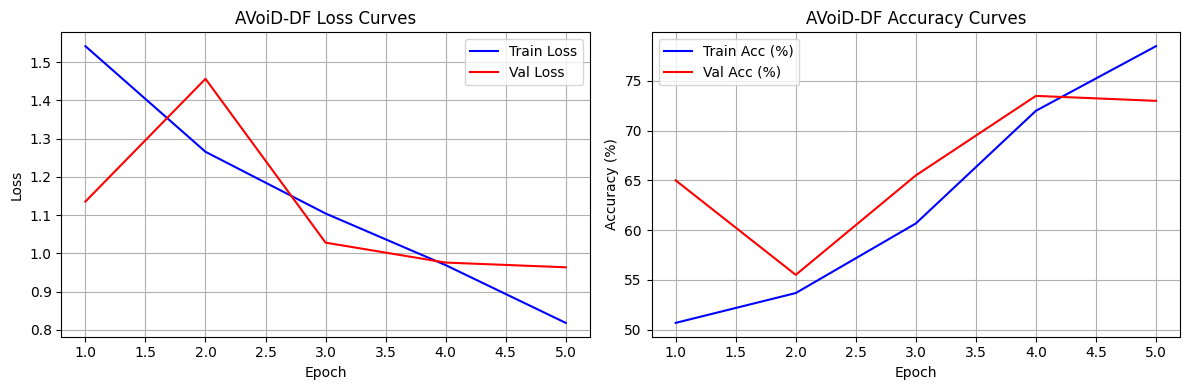

Saved training curves plot to: /kaggle/working/AVoiD_DF_results/AVoiD_DF_training_curves.png


In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(range(1, EPOCHS + 1), train_losses, label="Train Loss", color="blue")
ax1.plot(range(1, EPOCHS + 1), val_losses, label="Val Loss", color="red")
ax1.set_title("AVoiD-DF Loss Curves")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(range(1, EPOCHS + 1), [a*100 for a in train_accs], label="Train Acc (%)", color="blue")
ax2.plot(range(1, EPOCHS + 1), [a*100 for a in val_accs], label="Val Acc (%)", color="red")
ax2.set_title("AVoiD-DF Accuracy Curves")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
CURVES_PLOT_PATH = os.path.join(RESULTS_DIR, "AVoiD_DF_training_curves.png")
plt.savefig(CURVES_PLOT_PATH, dpi=300)
plt.show()
print(f"Saved training curves plot to: {CURVES_PLOT_PATH}")


### Section 16: Final Evaluation on 200-Video Test Split


In [34]:
if os.path.exists(BEST_CHECKPOINT):
    model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=device))
model.eval()

test_preds, test_targets, test_paths = [], [], []
with torch.no_grad():
    for v_b, a_b, l_b, p_b in test_loader:
        v_b, a_b = v_b.to(device), a_b.to(device)
        fo, _, _, _ = model(v_b, a_b)
        probs = torch.softmax(fo, dim=1)[:, 1].cpu().numpy()
        test_preds.extend(probs)
        test_targets.extend(l_b.numpy())
        test_paths.extend(p_b)

test_targets = np.array(test_targets)
test_preds = np.array(test_preds)
test_bin = (test_preds >= 0.5).astype(int)

acc = accuracy_score(test_targets, test_bin)
prec = precision_score(test_targets, test_bin, zero_division=0)
rec = recall_score(test_targets, test_bin, zero_division=0)
f1 = f1_score(test_targets, test_bin, zero_division=0)

try:
    auc = roc_auc_score(test_targets, test_preds)
except Exception:
    auc = 0.5

cm = confusion_matrix(test_targets, test_bin, labels=[0, 1])
tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)

print("=" * 60)
print("FINAL TEST EVALUATION METRICS (200-VIDEO SPLIT)")
print("=" * 60)
print(f"  Accuracy:                     {acc*100:.2f}%")
print(f"  Precision:                    {prec*100:.2f}%")
print(f"  Recall:                       {rec*100:.2f}%")
print(f"  F1-Score:                     {f1*100:.2f}%")
print(f"  ROC-AUC:                      {auc:.4f}")
print("-" * 60)
print("Confusion Matrix Breakdown:")
print(f"  True Negatives (Real Correct):   {tn}")
print(f"  False Positives (Real Incorrect): {fp}")
print(f"  False Negatives (Fake Incorrect): {fn}")
print(f"  True Positives (Fake Correct):   {tp}")
print("=" * 60)


FINAL TEST EVALUATION METRICS (200-VIDEO SPLIT)
  Accuracy:                     61.50%
  Precision:                    62.92%
  Recall:                       56.00%
  F1-Score:                     59.26%
  ROC-AUC:                      0.6815
------------------------------------------------------------
Confusion Matrix Breakdown:
  True Negatives (Real Correct):   67
  False Positives (Real Incorrect): 33
  False Negatives (Fake Incorrect): 44
  True Positives (Fake Correct):   56


### Section 17: Save Evaluation Artifacts to `/kaggle/working/`


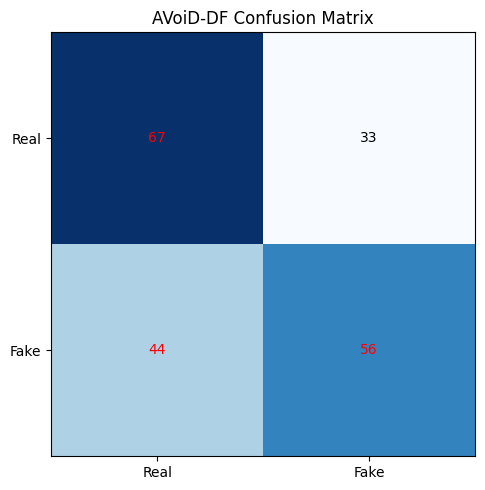

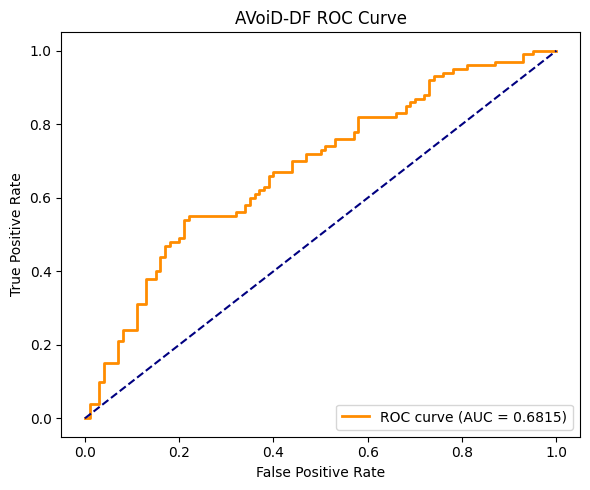

Saved metrics CSV to:      /kaggle/working/AVoiD_DF_results/AVoiD_DF_metrics.csv
Saved predictions CSV to:  /kaggle/working/AVoiD_DF_results/AVoiD_DF_test_predictions.csv
Saved confusion matrix to: /kaggle/working/AVoiD_DF_results/AVoiD_DF_confusion_matrix.png
Saved ROC curve plot to:   /kaggle/working/AVoiD_DF_results/AVoiD_DF_roc_curve.png


In [35]:
# 1. Save Metrics Summary CSV
metrics_df = pd.DataFrame([{
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec,
    "F1_Score": f1,
    "ROC_AUC": auc,
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp)
}])
METRICS_CSV_PATH = os.path.join(RESULTS_DIR, "AVoiD_DF_metrics.csv")
metrics_df.to_csv(METRICS_CSV_PATH, index=False)

# 2. Save Per-Sample Test Predictions CSV
pred_df = pd.DataFrame({
    "video_path": [os.path.basename(p) for p in test_paths],
    "ground_truth": test_targets,
    "predicted_probability": test_preds,
    "predicted_label": test_bin
})
PRED_CSV_PATH = os.path.join(RESULTS_DIR, "AVoiD_DF_test_predictions.csv")
pred_df.to_csv(PRED_CSV_PATH, index=False)

# 3. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap=plt.cm.Blues)
ax.set_title("AVoiD-DF Confusion Matrix")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Real", "Fake"])
ax.set_yticklabels(["Real", "Fake"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="red" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout()
CM_PLOT_PATH = os.path.join(RESULTS_DIR, "AVoiD_DF_confusion_matrix.png")
plt.savefig(CM_PLOT_PATH, dpi=300)
plt.show()

# 4. Plot ROC Curve
fpr, tpr, _ = roc_curve(test_targets, test_preds)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AVoiD-DF ROC Curve')
plt.legend(loc="lower right")
plt.tight_layout()
ROC_PLOT_PATH = os.path.join(RESULTS_DIR, "AVoiD_DF_roc_curve.png")
plt.savefig(ROC_PLOT_PATH, dpi=300)
plt.show()

print(f"Saved metrics CSV to:      {METRICS_CSV_PATH}")
print(f"Saved predictions CSV to:  {PRED_CSV_PATH}")
print(f"Saved confusion matrix to: {CM_PLOT_PATH}")
print(f"Saved ROC curve plot to:   {ROC_PLOT_PATH}")


### Section 18: Single Video Multimodal Inference Function


In [36]:
def predict_single_sample(video_path):
    temp_dataset = LAVDFDataset([video_path], [0], is_train=False)
    v_tensor, a_tensor, _, _ = temp_dataset[0]
    v_tensor = v_tensor.unsqueeze(0).to(device)
    a_tensor = a_tensor.unsqueeze(0).to(device)
    
    model.eval()
    with torch.no_grad():
        fo, vo, ao, _ = model(v_tensor, a_tensor)
        f_prob = torch.softmax(fo, dim=1)[0, 1].item()
        v_prob = torch.softmax(vo, dim=1)[0, 1].item()
        a_prob = torch.softmax(ao, dim=1)[0, 1].item()
        
    inconsistency = abs(v_prob - a_prob)
    verdict = "FAKE" if f_prob >= 0.5 else "REAL / GENUINE"
    
    print("=" * 60)
    print("SINGLE SAMPLE MULTIMODAL INFERENCE DEMONSTRATION")
    print("=" * 60)
    print(f"  Target Video:                 {os.path.basename(video_path)}")
    print(f"  Visual Modality Score:        {v_prob * 100:.2f}%")
    print(f"  Audio Modality Score:         {a_prob * 100:.2f}%")
    print(f"  Audio-Visual Inconsistency:   {inconsistency * 100:.2f}%")
    print(f"  Fusion Deepfake Probability:  {f_prob * 100:.2f}%")
    print(f"  FINAL PREDICTION:             {verdict}")
    print("=" * 60)

demo_sample = test_paths[0] if len(test_paths) > 0 else (train_videos[0] if len(train_videos) > 0 else "demo.mp4")
predict_single_sample(demo_sample)


SINGLE SAMPLE MULTIMODAL INFERENCE DEMONSTRATION
  Target Video:                 096011.mp4
  Visual Modality Score:        55.39%
  Audio Modality Score:         81.87%
  Audio-Visual Inconsistency:   26.48%
  Fusion Deepfake Probability:  85.91%
  FINAL PREDICTION:             FAKE


## Notebook Execution Summary
AVoiD-DF pipeline execution finished successfully! All weights, metrics, plots, and metadata splits have been written to `/kaggle/working/AVoiD_DF_results/`.
